<a href="https://colab.research.google.com/github/manikanta-eng/block-chain-/blob/main/assignment_7_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##2303A51271  P.Manikanta  Batch-08

In [1]:
!pip install -q web3 eth-tester py-evm py-solc-x pandas matplotlib

In [2]:
import solcx
import pandas as pd
import matplotlib.pyplot as plt

from web3 import Web3
from solcx import compile_source
from eth_tester.exceptions import TransactionFailed

print("Libraries imported successfully")

Libraries imported successfully


In [3]:
SOLIDITY_VERSION = "0.8.20"

solcx.install_solc(SOLIDITY_VERSION)
solcx.set_solc_version(SOLIDITY_VERSION)

print("Solidity compiler installed:", SOLIDITY_VERSION)

Solidity compiler installed: 0.8.20


In [4]:
w3 = Web3(Web3.EthereumTesterProvider())

accounts = w3.eth.accounts

owner = accounts[0]
user1 = accounts[1]
user2 = accounts[2]

print("Blockchain connected:", w3.is_connected())
print("Owner account:", owner)
print("User account:", user1)
print("Available accounts:", len(accounts))
print("Initial balance:", w3.from_wei(
    w3.eth.get_balance(owner), "ether"
), "ETH")

Blockchain connected: True
Owner account: 0x7E5F4552091A69125d5DfCb7b8C2659029395Bdf
User account: 0x2B5AD5c4795c026514f8317c7a215E218DcCD6cF
Available accounts: 10
Initial balance: 1000000 ETH


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [5]:
solidity_code = """

// SPDX-License-Identifier: MIT
pragma solidity ^0.8.20;

// =====================================
// 1. VULNERABLE BANK - REENTRANCY
// =====================================

contract VulnerableBank {

    mapping(address => uint256) public balances;

    function deposit() public payable {
        balances[msg.sender] += msg.value;
    }

    function withdraw() public {

        uint256 amount = balances[msg.sender];

        require(amount > 0, "Insufficient balance");

        (bool success, ) = payable(msg.sender).call{
            value: amount
        }("");

        require(success, "Transfer failed");

        balances[msg.sender] = 0;
    }
}


// =====================================
// 2. SECURE BANK
// =====================================

contract SecureBank {

    mapping(address => uint256) public balances;

    bool private locked;

    modifier nonReentrant() {
        require(!locked, "Reentrant call detected");

        locked = true;
        _;
        locked = false;
    }

    function deposit() public payable {
        balances[msg.sender] += msg.value;
    }

    function withdraw() public nonReentrant {

        uint256 amount = balances[msg.sender];

        require(amount > 0, "Insufficient balance");

        // Checks-Effects-Interactions
        balances[msg.sender] = 0;

        (bool success, ) = payable(msg.sender).call{
            value: amount
        }("");

        require(success, "Transfer failed");
    }
}


// =====================================
// 3. LOCAL REENTRANCY TEST CONTRACT
// =====================================

interface IBank {

    function deposit() external payable;

    function withdraw() external;
}

contract ReentrancyTester {

    IBank public bank;

    constructor(address bankAddress) {
        bank = IBank(bankAddress);
    }

    function attack() public payable {

        require(msg.value >= 1 ether, "Minimum 1 ETH");

        bank.deposit{value: msg.value}();

        bank.withdraw();
    }

    receive() external payable {

        if (address(bank).balance >= 1 ether) {
            bank.withdraw();
        }
    }
}


// =====================================
// 4. VULNERABLE INTEGER ARITHMETIC
// =====================================

contract VulnerableArithmetic {

    function add(uint8 a, uint8 b)
        public
        pure
        returns (uint8)
    {
        unchecked {
            return a + b;
        }
    }
}


// =====================================
// 5. SECURE INTEGER ARITHMETIC
// =====================================

contract SecureArithmetic {

    function add(uint8 a, uint8 b)
        public
        pure
        returns (uint8)
    {
        return a + b;
    }
}


// =====================================
// 6. VULNERABLE ACCESS CONTROL
// =====================================

contract VulnerableAccess {

    uint256 public value;

    function setValue(uint256 newValue) public {
        value = newValue;
    }
}


// =====================================
// 7. SECURE ACCESS CONTROL
// =====================================

contract SecureAccess {

    address public owner;

    uint256 public value;

    constructor() {
        owner = msg.sender;
    }

    modifier onlyOwner() {
        require(msg.sender == owner, "Not authorized");
        _;
    }

    function setValue(uint256 newValue)
        public
        onlyOwner
    {
        value = newValue;
    }
}

"""
print("All Solidity contracts created successfully")

All Solidity contracts created successfully


In [6]:
compiled_sol = compile_source(
    solidity_code,
    output_values=["abi", "bin"]
)

print("Compilation successful!")
print("Total contracts:", len(compiled_sol))

for contract_name in compiled_sol:
    print("Compiled:", contract_name.split(":")[-1])

Compilation successful!
Total contracts: 8
Compiled: IBank
Compiled: ReentrancyTester
Compiled: SecureAccess
Compiled: SecureArithmetic
Compiled: SecureBank
Compiled: VulnerableAccess
Compiled: VulnerableArithmetic
Compiled: VulnerableBank


In [7]:
def deploy_contract(contract_name, sender=owner):

    contract_data = compiled_sol[
        "<stdin>:" + contract_name
    ]

    Contract = w3.eth.contract(
        abi=contract_data["abi"],
        bytecode=contract_data["bin"]
    )

    tx_hash = Contract.constructor().transact({
        "from": sender,
        "gas": 5000000
    })

    receipt = w3.eth.wait_for_transaction_receipt(tx_hash)

    if receipt.status != 1:
        raise Exception("Contract deployment failed")

    deployed = w3.eth.contract(
        address=receipt.contractAddress,
        abi=contract_data["abi"]
    )

    print(contract_name, "deployed at:", receipt.contractAddress)

    return deployed


def deploy_with_args(contract_name, args, sender=owner):

    contract_data = compiled_sol[
        "<stdin>:" + contract_name
    ]

    Contract = w3.eth.contract(
        abi=contract_data["abi"],
        bytecode=contract_data["bin"]
    )

    tx_hash = Contract.constructor(*args).transact({
        "from": sender,
        "gas": 5000000
    })

    receipt = w3.eth.wait_for_transaction_receipt(tx_hash)

    if receipt.status != 1:
        raise Exception("Deployment failed")

    return w3.eth.contract(
        address=receipt.contractAddress,
        abi=contract_data["abi"]
    )


print("Deployment functions ready")

Deployment functions ready


In [8]:
vulnerable_bank = deploy_contract("VulnerableBank")

secure_bank = deploy_contract("SecureBank")

vulnerable_arithmetic = deploy_contract(
    "VulnerableArithmetic"
)

secure_arithmetic = deploy_contract(
    "SecureArithmetic"
)

vulnerable_access = deploy_contract(
    "VulnerableAccess"
)

secure_access = deploy_contract(
    "SecureAccess"
)

print("\nAll main contracts deployed successfully")

VulnerableBank deployed at: 0xF2E246BB76DF876Cef8b38ae84130F4F55De395b
SecureBank deployed at: 0x2946259E0334f33A064106302415aD3391BeD384
VulnerableArithmetic deployed at: 0xDe09E74d4888Bc4e65F589e8c13Bce9F71DdF4c7
SecureArithmetic deployed at: 0x51a240271AB8AB9f9a21C82d9a85396b704E164d
VulnerableAccess deployed at: 0xB9816fC57977D5A786E654c7CF76767be63b966e
SecureAccess deployed at: 0x6D411e0A54382eD43F02410Ce1c7a7c122afA6E1

All main contracts deployed successfully


In [9]:
ETHER = 10**18

# Fund vulnerable bank with 10 ETH
tx = vulnerable_bank.functions.deposit().transact({
    "from": owner,
    "value": 10 * ETHER
})

w3.eth.wait_for_transaction_receipt(tx)

# Deploy test contract
attacker_vulnerable = deploy_with_args(
    "ReentrancyTester",
    [vulnerable_bank.address]
)

bank_before = w3.from_wei(
    w3.eth.get_balance(vulnerable_bank.address),
    "ether"
)

print("Vulnerable bank before test:", bank_before, "ETH")

# Run controlled local reentrancy test
tx = attacker_vulnerable.functions.attack().transact({
    "from": user1,
    "value": 1 * ETHER,
    "gas": 3000000
})

receipt = w3.eth.wait_for_transaction_receipt(tx)

bank_after = w3.from_wei(
    w3.eth.get_balance(vulnerable_bank.address),
    "ether"
)

tester_balance = w3.from_wei(
    w3.eth.get_balance(attacker_vulnerable.address),
    "ether"
)

print("\nReentrancy test completed")
print("Transaction status:", receipt.status)
print("Bank balance after test:", bank_after, "ETH")
print("Test contract balance:", tester_balance, "ETH")

Vulnerable bank before test: 10 ETH

Reentrancy test completed
Transaction status: 1
Bank balance after test: 0 ETH
Test contract balance: 11 ETH


In [10]:
# Fund secure bank with 10 ETH

tx = secure_bank.functions.deposit().transact({
    "from": owner,
    "value": 10 * ETHER
})

w3.eth.wait_for_transaction_receipt(tx)

# Deploy tester for secure bank

attacker_secure = deploy_with_args(
    "ReentrancyTester",
    [secure_bank.address]
)

secure_before = w3.from_wei(
    w3.eth.get_balance(secure_bank.address),
    "ether"
)

print("Secure bank before test:", secure_before, "ETH")

try:

    tx = attacker_secure.functions.attack().transact({
        "from": user2,
        "value": 1 * ETHER,
        "gas": 3000000
    })

    receipt = w3.eth.wait_for_transaction_receipt(tx)

    if receipt.status == 0:
        print("Reentrancy attack blocked")

except Exception as e:

    print("Reentrancy attack blocked successfully")

secure_after = w3.from_wei(
    w3.eth.get_balance(secure_bank.address),
    "ether"
)

print("Secure bank after test:", secure_after, "ETH")

assert secure_after == secure_before

print("Secure contract passed the balance protection test")

Secure bank before test: 10 ETH
Reentrancy attack blocked
Secure bank after test: 10 ETH
Secure contract passed the balance protection test


In [11]:
# Vulnerable arithmetic: uint8 maximum is 255

vulnerable_result = vulnerable_arithmetic.functions.add(
    250, 10
).call()

print("Vulnerable Arithmetic")
print("250 + 10 =", vulnerable_result)

# Secure arithmetic

print("\nSecure Arithmetic")

try:

    secure_result = secure_arithmetic.functions.add(
        250, 10
    ).call()

    print("Result:", secure_result)

except Exception:

    print("Overflow detected!")
    print("Secure contract rejected the calculation")

assert vulnerable_result == 4

print("\nInteger overflow protection verified")

Vulnerable Arithmetic
250 + 10 = 4

Secure Arithmetic
Overflow detected!
Secure contract rejected the calculation

Integer overflow protection verified


In [12]:
print("Vulnerable Access Control")

# Any account can modify the value

tx = vulnerable_access.functions.setValue(
    100
).transact({"from": user1})

w3.eth.wait_for_transaction_receipt(tx)

print("Unauthorized user changed value to:",
      vulnerable_access.functions.value().call())


print("\nSecure Access Control")

# Owner changes the value

tx = secure_access.functions.setValue(
    200
).transact({"from": owner})

w3.eth.wait_for_transaction_receipt(tx)

print("Owner changed value to:",
      secure_access.functions.value().call())


# Unauthorized user tries to change the value

try:

    secure_access.functions.setValue(
        500
    ).call({"from": user1})

    print("Unexpected: unauthorized access allowed")

except Exception:

    print("Unauthorized access blocked successfully")


assert secure_access.functions.value().call() == 200

print("Access control protection verified")

Vulnerable Access Control
Unauthorized user changed value to: 100

Secure Access Control
Owner changed value to: 200
Unauthorized access blocked successfully
Access control protection verified


In [13]:
results = pd.DataFrame({

    "Security Vulnerability": [
        "Reentrancy",
        "Integer Overflow",
        "Improper Access Control"
    ],

    "Vulnerable Contract": [
        "VulnerableBank",
        "VulnerableArithmetic",
        "VulnerableAccess"
    ],

    "Secure Contract": [
        "SecureBank",
        "SecureArithmetic",
        "SecureAccess"
    ],

    "Vulnerable Status": [
        "Attack Successful",
        "Overflow Occurred",
        "Unauthorized Access Allowed"
    ],

    "Secure Status": [
        "Attack Blocked",
        "Overflow Reverted",
        "Unauthorized Access Blocked"
    ],

    "Protection": [
        "Checks-Effects-Interactions + Reentrancy Guard",
        "Solidity Checked Arithmetic",
        "onlyOwner Modifier"
    ]

})

display(results)

,Security Vulnerability,Vulnerable Contract,Secure Contract,Vulnerable Status,Secure Status,Protection
0,Reentrancy,VulnerableBank,SecureBank,Attack Successful,Attack Blocked,Checks-Effects-Interactions + Reentrancy Guard
1,Integer Overflow,VulnerableArithmetic,SecureArithmetic,Overflow Occurred,Overflow Reverted,Solidity Checked Arithmetic
2,Improper Access Control,VulnerableAccess,SecureAccess,Unauthorized Access Allowed,Unauthorized Access Blocked,onlyOwner Modifier


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


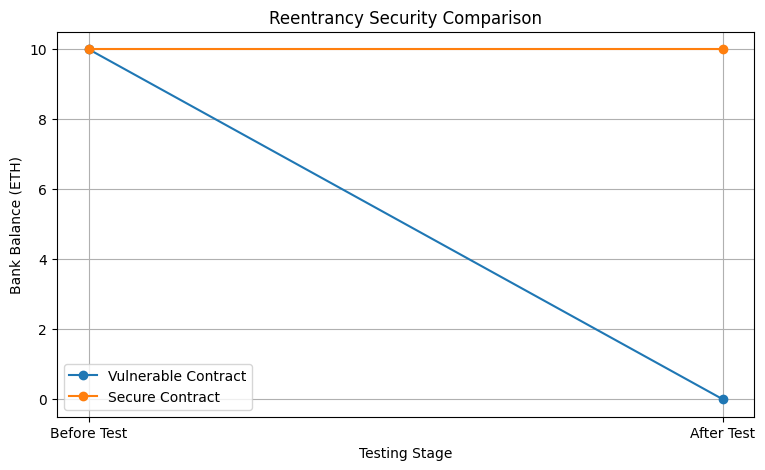

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [14]:
labels = [
    "Before Test",
    "After Test"
]

vulnerable_values = [
    float(bank_before),
    float(bank_after)
]

secure_values = [
    float(secure_before),
    float(secure_after)
]

x = range(len(labels))

plt.figure(figsize=(9, 5))

plt.plot(
    x,
    vulnerable_values,
    marker="o",
    label="Vulnerable Contract"
)

plt.plot(
    x,
    secure_values,
    marker="o",
    label="Secure Contract"
)

plt.xticks(x, labels)

plt.xlabel("Testing Stage")
plt.ylabel("Bank Balance (ETH)")

plt.title("Reentrancy Security Comparison")

plt.legend()
plt.grid(True)

plt.show()

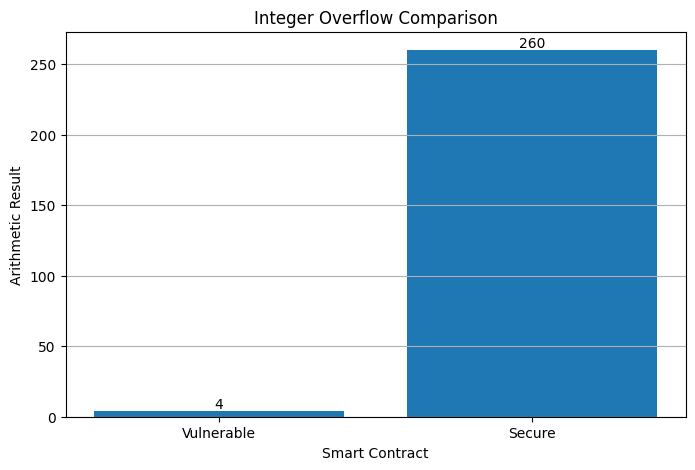

Expected mathematical result: 260
Vulnerable result: 4
Secure contract: Overflow rejected


In [15]:
models = [
    "Vulnerable",
    "Secure"
]

values = [
    vulnerable_result,
    260
]

plt.figure(figsize=(8, 5))

bars = plt.bar(models, values)

plt.title("Integer Overflow Comparison")

plt.xlabel("Smart Contract")
plt.ylabel("Arithmetic Result")

plt.bar_label(bars)

plt.grid(axis="y")

plt.show()

print("Expected mathematical result: 260")
print("Vulnerable result:", vulnerable_result)
print("Secure contract: Overflow rejected")

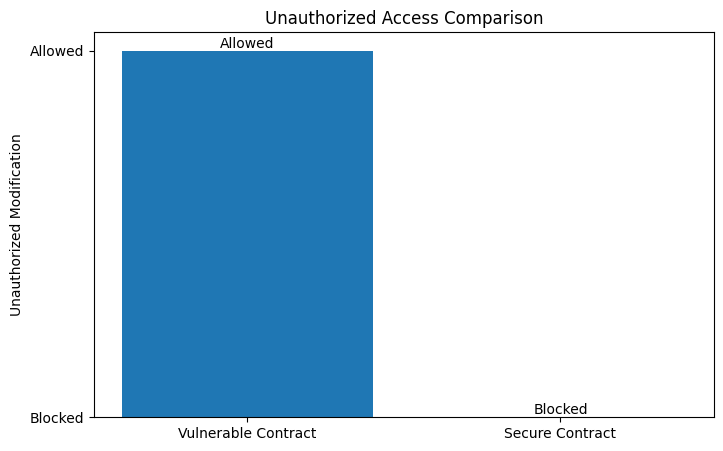

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [16]:
access_labels = [
    "Vulnerable Contract",
    "Secure Contract"
]

access_values = [
    1,
    0
]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    access_labels,
    access_values
)

plt.title("Unauthorized Access Comparison")

plt.ylabel("Unauthorized Modification")

plt.yticks([0, 1], ["Blocked", "Allowed"])

plt.bar_label(
    bars,
    labels=["Allowed", "Blocked"]
)

plt.show()

In [17]:
security_results = pd.DataFrame({

    "Test": [
        "Reentrancy",
        "Integer Overflow",
        "Improper Access Control"
    ],

    "Vulnerable Contract": [
        "Failed",
        "Failed",
        "Failed"
    ],

    "Secure Contract": [
        "Passed",
        "Passed",
        "Passed"
    ]

})

display(security_results)

print("\n========== FINAL RESULTS ==========")

print("1. Reentrancy protection tested")
print("2. Integer overflow protection tested")
print("3. Access control protection tested")

print("\nAll three security protections verified!")

,Test,Vulnerable Contract,Secure Contract
0,Reentrancy,Failed,Passed
1,Integer Overflow,Failed,Passed
2,Improper Access Control,Failed,Passed



========== FINAL RESULTS ==========
1. Reentrancy protection tested
2. Integer overflow protection tested
3. Access control protection tested

All three security protections verified!


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [18]:
results.to_csv(
    "smart_contract_security_results.csv",
    index=False
)

security_results.to_csv(
    "security_test_summary.csv",
    index=False
)

print("CSV reports generated successfully")

from google.colab import files

files.download("smart_contract_security_results.csv")

files.download("security_test_summary.csv")

CSV reports generated successfully


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>